# Lab 01 - Tasks 4 to 9

Put `Sukuna.jpeg` (and `Gojo.jpg` for Task 8) in the same folder as this notebook.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Task 4: Interactive Geometry & Blank Canvas

Canvas center: (400, 400)


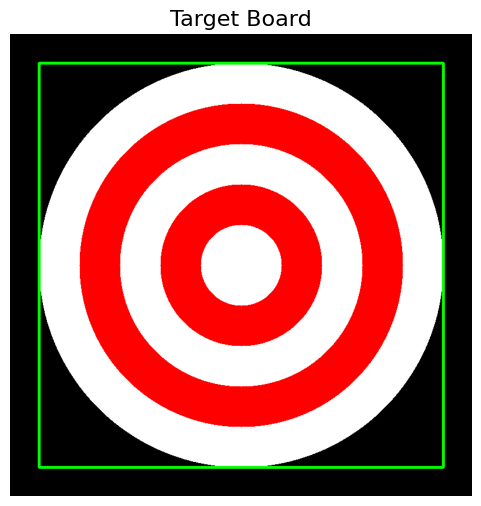

In [2]:
# 800x800 black canvas
canvas = np.zeros((800, 800, 3), dtype=np.uint8)
center = (400, 400)

# 5 circles from biggest to smallest, alternating white and red
radii = [350, 280, 210, 140, 70]
colors = [(255, 255, 255), (0, 0, 255), (255, 255, 255), (0, 0, 255), (255, 255, 255)]

for i in range(5):
    cv2.circle(canvas, center, radii[i], colors[i], -1)

# bounding box around the outer circle
cv2.rectangle(canvas, (400 - 350, 400 - 350), (400 + 350, 400 + 350), (0, 255, 0), 3)

# center of the canvas
h, w = canvas.shape[:2]
cx = w // 2
cy = h // 2
print("Canvas center:", (cx, cy))

canvas_rgb = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 6))
plt.imshow(canvas_rgb)
plt.title('Target Board', fontsize=16)
plt.axis('off')
plt.show()

## Task 5: Advanced Blurring & NumPy ROI Extraction

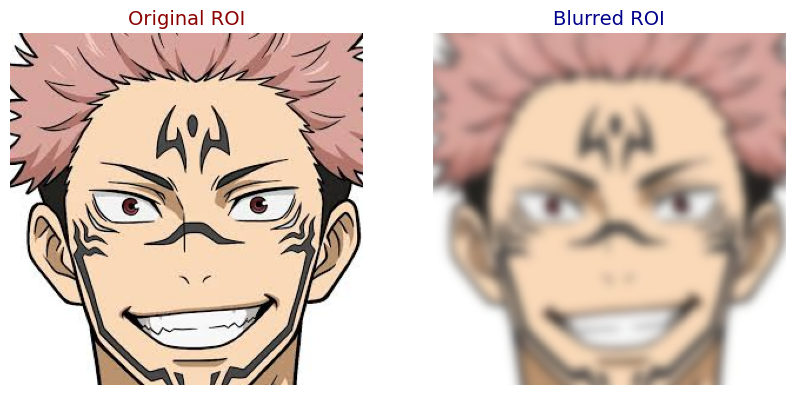

In [5]:
img = cv2.imread('/content/Sukuna.jfif')

if img is None:
    print("Error: Image not found.")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    blurred = cv2.GaussianBlur(img, (25, 25), 0)

    h, w = img.shape[:2]
    cy = h // 2
    cx = w // 2

    # 300x300 region from the exact center
    roi_orig = img[cy - 150:cy + 150, cx - 150:cx + 150]
    roi_blur = blurred[cy - 150:cy + 150, cx - 150:cx + 150]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(roi_orig)
    axes[0].axis('off')
    axes[0].set_title('Original ROI', fontsize=14, color='darkred')

    axes[1].imshow(roi_blur)
    axes[1].axis('off')
    axes[1].set_title('Blurred ROI', fontsize=14, color='darkblue')

    plt.show()

## Task 6: Alpha Blending & Typography

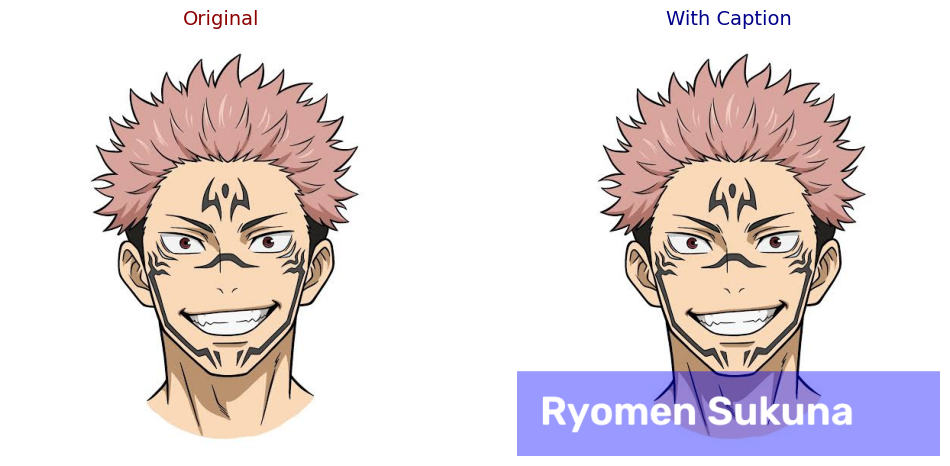

In [6]:
img = cv2.imread('/content/Sukuna.jfif')

if img is None:
    print("Error: Image not found.")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    box_top = int(h * 0.8)  # bottom 20%

    # solid blue rectangle (RGB)
    overlay = img.copy()
    cv2.rectangle(overlay, (0, box_top), (w, h), (0, 0, 255), -1)

    # blend so the rectangle is semi-transparent
    result = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)

    # title on top of the box
    cv2.putText(result, 'Ryomen Sukuna', (30, box_top + 70),
                cv2.FONT_HERSHEY_SIMPLEX, 1.8, (255, 255, 255), 3)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(img)
    axes[0].axis('off')
    axes[0].set_title('Original', fontsize=14, color='darkred')

    axes[1].imshow(result)
    axes[1].axis('off')
    axes[1].set_title('With Caption', fontsize=14, color='darkblue')

    plt.show()

## Task 7: Matrix-Based Rotation & Adaptive Thresholding

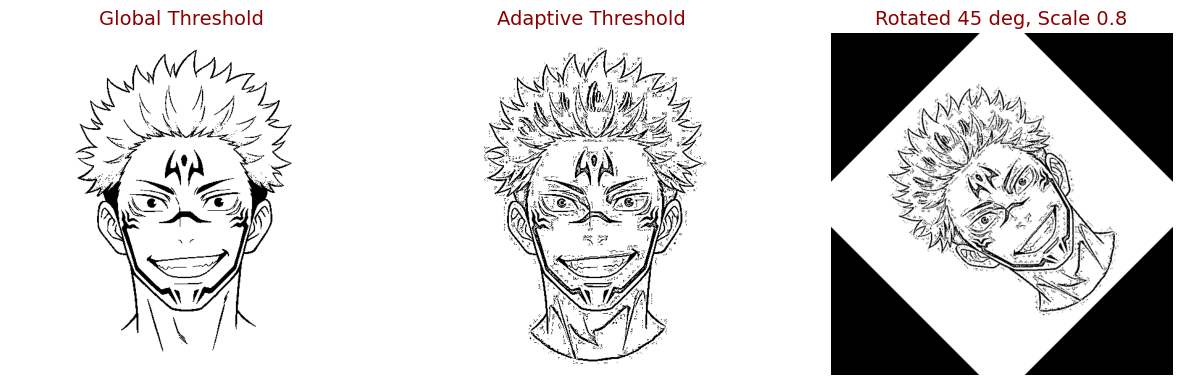

In [7]:
gray = cv2.imread('/content/Sukuna.jfif', cv2.IMREAD_GRAYSCALE)

if gray is None:
    print("Error: Image not found.")
else:
    # global thresholding
    _, global_thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

    # adaptive thresholding
    adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, 11, 2)

    # rotate the adaptive output by 45 degrees and scale it by 0.8
    h, w = adaptive.shape
    M = cv2.getRotationMatrix2D((w // 2, h // 2), 45, 0.8)
    rotated = cv2.warpAffine(adaptive, M, (w, h))

    images = [global_thresh, adaptive, rotated]
    titles = ['Global Threshold', 'Adaptive Threshold', 'Rotated 45 deg, Scale 0.8']

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for i in range(3):
        axes[i].imshow(images[i], cmap='gray')
        axes[i].axis('off')
        axes[i].set_title(titles[i], fontsize=14, color='darkred')

    plt.show()

## Task 8: Masking with Bitwise Logic

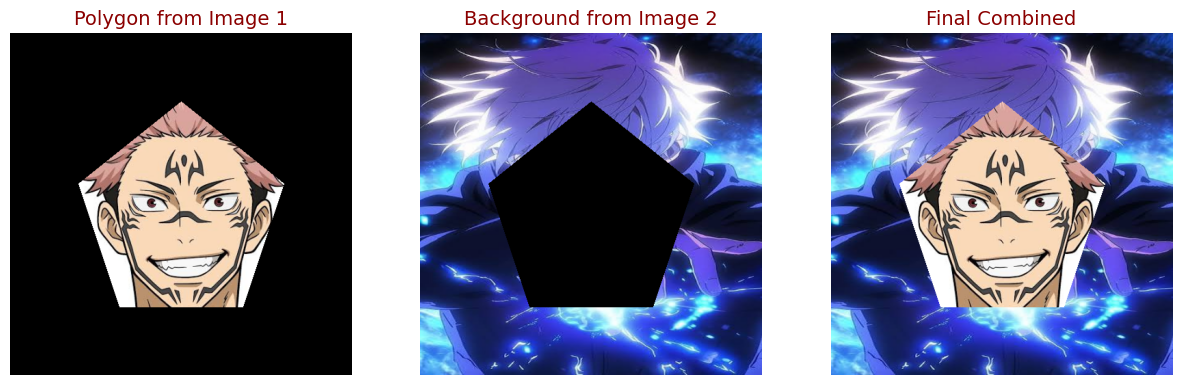

In [8]:
img1 = cv2.imread('/content/Sukuna.jfif')
img2 = cv2.imread('/content/Gojo.jfif')

if img1 is None or img2 is None:
    print("Error: Image not found.")
else:
    # same size for both images
    img1 = cv2.resize(img1, (500, 500))
    img2 = cv2.resize(img2, (500, 500))

    # black mask with a thick white polygon in the center
    mask = np.zeros((500, 500), dtype=np.uint8)
    pts = np.array([[250, 100], [400, 220], [340, 400], [160, 400], [100, 220]], np.int32)
    cv2.fillPoly(mask, [pts], 255)

    inv_mask = cv2.bitwise_not(mask)

    cut_img1 = cv2.bitwise_and(img1, img1, mask=mask)          # polygon from image 1
    cut_img2 = cv2.bitwise_and(img2, img2, mask=inv_mask)      # background from image 2
    combined = cv2.bitwise_or(cut_img1, cut_img2)

    shown = [cut_img1, cut_img2, combined]
    titles = ['Polygon from Image 1', 'Background from Image 2', 'Final Combined']

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for i in range(3):
        axes[i].imshow(cv2.cvtColor(shown[i], cv2.COLOR_BGR2RGB))
        axes[i].axis('off')
        axes[i].set_title(titles[i], fontsize=14, color='darkred')

    plt.show()

## Task 9: Statistical Image Profiling with Pandas

In [9]:
img = cv2.imread('/content/Sukuna.jfif')


if img is None:
    print("Error: Image not found.")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # flatten each color channel into a 1D array
    red = img[:, :, 0].flatten()
    green = img[:, :, 1].flatten()
    blue = img[:, :, 2].flatten()

    df = pd.DataFrame({'Red': red, 'Green': green, 'Blue': blue})

    print(df.describe())

                 Red          Green           Blue
count  306916.000000  306916.000000  306916.000000
mean      233.371796     221.309476     214.557045
std        51.975657      59.332436      63.423833
min         0.000000       0.000000       0.000000
25%       246.000000     217.000000     184.000000
50%       255.000000     255.000000     255.000000
75%       255.000000     255.000000     255.000000
max       255.000000     255.000000     255.000000
